<a href="https://colab.research.google.com/github/phongdpm245476-tech/dpm245476_PhanChiPhong_25PM.Python_Nh4_To3_NopBaiTapChuong/blob/main/PPNCKH1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


DATASET: Iris
So mau: 150
So dac trung: 4

DATASET: Wine
So mau: 178
So dac trung: 13

DATASET: Breast Cancer
So mau: 569
So dac trung: 30

===== KET QUA 9 THUC NGHIEM =====
      Dataset     Algorithm  Accuracy  Precision  Recall  F1-score
         Iris           KNN    0.9333     0.9444  0.9333    0.9327
         Iris Decision Tree    0.9333     0.9333  0.9333    0.9333
         Iris Random Forest    0.9000     0.9024  0.9000    0.8997
         Wine           KNN    0.9722     0.9697  0.9762    0.9718
         Wine Decision Tree    0.9444     0.9583  0.9389    0.9457
         Wine Random Forest    1.0000     1.0000  1.0000    1.0000
Breast Cancer           KNN    0.9561     0.9551  0.9504    0.9526
Breast Cancer Decision Tree    0.9123     0.9019  0.9157    0.9075
Breast Cancer Random Forest    0.9561     0.9551  0.9504    0.9526


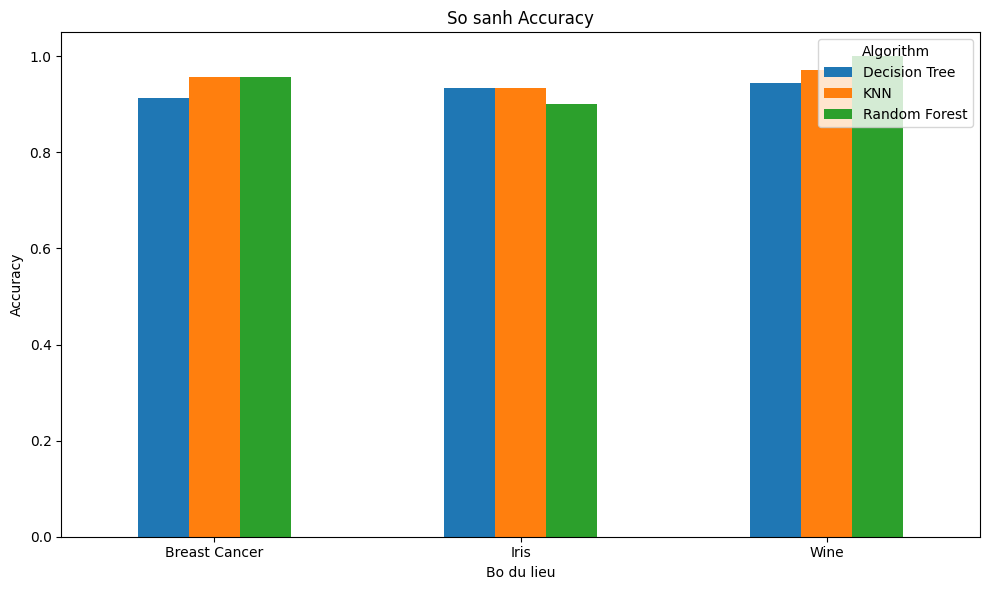

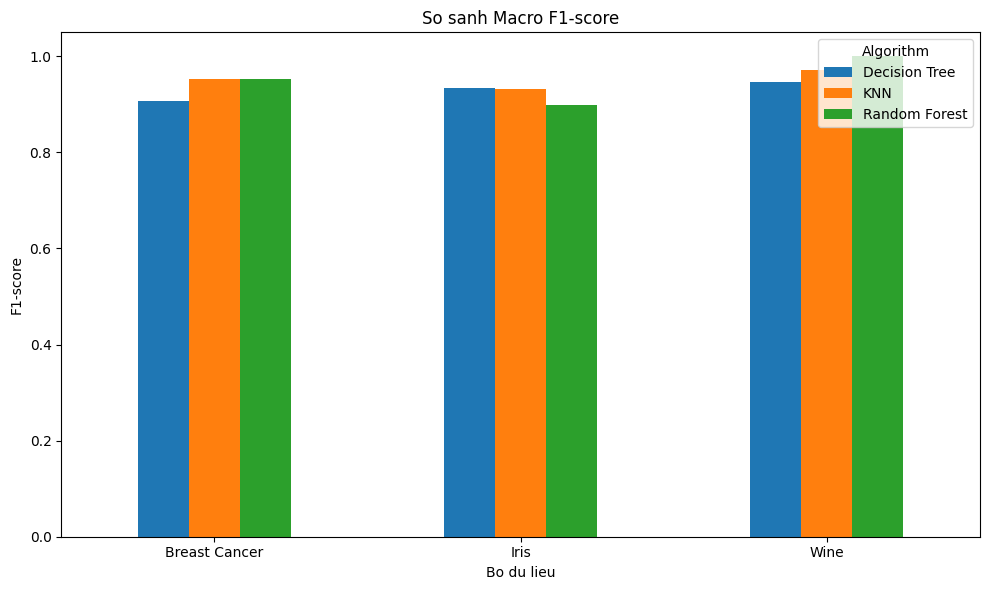


===== MO HINH ACCURACY CAO NHAT =====
      Dataset     Algorithm  Accuracy  F1-score
Breast Cancer           KNN    0.9561    0.9526
         Iris           KNN    0.9333    0.9327
         Wine Random Forest    1.0000    1.0000

Da hoan thanh!
File ket qua: ket_qua_thuc_nghiem.csv
Bieu do: accuracy.png va f1_score.png


In [1]:

# =====================================================
# BAI THUC HANH MACHINE LEARNING
# 3 THUAT TOAN x 3 BO DU LIEU = 9 THUC NGHIEM
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (
    load_iris,
    load_wine,
    load_breast_cancer
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# BUOC 1: NAP DU LIEU
datasets = {
    "Iris": load_iris(),
    "Wine": load_wine(),
    "Breast Cancer": load_breast_cancer()
}

# BUOC 2: KHAI BAO THUAT TOAN
models = {
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

# BUOC 3: THUC NGHIEM
for data_name, data in datasets.items():

    X = data.data
    y = data.target

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print("\nDATASET:", data_name)
    print("So mau:", len(X))
    print("So dac trung:", X.shape[1])

    for model_name, model in models.items():

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append({
            "Dataset": data_name,
            "Algorithm": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test, y_pred,
                average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred,
                average="macro", zero_division=0
            ),
            "F1-score": f1_score(
                y_test, y_pred,
                average="macro", zero_division=0
            )
        })

# BUOC 4: IN BANG KET QUA
df = pd.DataFrame(results)

print("\n===== KET QUA 9 THUC NGHIEM =====")
print(df.round(4).to_string(index=False))

# BUOC 5: VE BIEU DO ACCURACY
pivot_acc = df.pivot(
    index="Dataset",
    columns="Algorithm",
    values="Accuracy"
)

pivot_acc.plot(kind="bar", figsize=(10, 6), ylim=(0, 1.05))
plt.title("So sanh Accuracy")
plt.xlabel("Bo du lieu")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("accuracy.png", dpi=300)
plt.show()

# BUOC 6: VE BIEU DO F1-SCORE
pivot_f1 = df.pivot(
    index="Dataset",
    columns="Algorithm",
    values="F1-score"
)

pivot_f1.plot(kind="bar", figsize=(10, 6), ylim=(0, 1.05))
plt.title("So sanh Macro F1-score")
plt.xlabel("Bo du lieu")
plt.ylabel("F1-score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("f1_score.png", dpi=300)
plt.show()

# BUOC 7: TIM MO HINH TOT NHAT THEO ACCURACY
best = df.loc[df.groupby("Dataset")["Accuracy"].idxmax()]

print("\n===== MO HINH ACCURACY CAO NHAT =====")
print(best[["Dataset", "Algorithm", "Accuracy", "F1-score"]]
      .round(4).to_string(index=False))

# BUOC 8: LUU KET QUA
df.to_csv("ket_qua_thuc_nghiem.csv",
          index=False, encoding="utf-8-sig")

print("\nDa hoan thanh!")
print("File ket qua: ket_qua_thuc_nghiem.csv")
print("Bieu do: accuracy.png va f1_score.png")
